# MACHINE LEARNING & DEEP LEARNING

---

## CASO PRÁCTICO

Una empresa industrial posee diferentes máquinas trabajando durante varias horas diariamente.

Los sensores registran:
* Temperatura
* Vibración
* Presión
* Horas de funcionamiento
* Días desde el último mantenimiento

Históricamente, la empresa también conoce si después de cada conjunto de mediciones se produjo una falla. Esta información se almacena en una base de datos MySQL. Actualmente el mantenimiento se realiza principalmente cuando: La máquina presenta una falla

Esto produce:
* Paradas de producción
* Pérdida de tiempo
* Costos de mantenimiento correctivo
* Retrasos en pedidos
* Menor productividad

Crear un modelo de aprendizaje supervisado capaz de estimar:

> 0 = funcionamiento normal  
> 1 = posible falla

In [22]:
# !pip install ipykernel pandas sqlalchemy pymysql scikit-learn matplotlib
# !pip freeze > requirements.txt

## PASO 1. IMPORTAR LIBRERÍAS

In [23]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


## PASO 2. CONECTARSE A MYSQL

In [24]:
conexion = create_engine("mysql+pymysql://root:@localhost:3306/mantenimiento_ml")

## PASO 3. CONSULTAR LOS DATOS

In [25]:
consulta = """
SELECT temperatura, vibracion, presion,
horas_operacion, dias_mantenimiento, falla
FROM lecturas_maquinas
"""

In [26]:

df = pd.read_sql(consulta, conexion)


## PASO 4. EXPLORAR LA INFORMACIÓN

In [27]:
df.head(100)

,temperatura,vibracion,presion,horas_operacion,dias_mantenimiento,falla
0,83.89,8.95,123.59,4698,82,0
1,95.17,1.29,116.62,5242,6,0
2,83.23,8.39,105.29,3504,115,0
3,65.86,8.43,128.29,9720,143,0
4,61.23,8.07,138.65,8326,116,0
...,...,...,...,...,...,...
95,95.66,4.24,88.80,5527,66,1
96,67.02,8.07,107.97,6460,3,1
97,65.63,6.97,142.56,4840,129,0
98,65.16,5.55,90.00,2042,100,0


In [28]:
df.shape

(1000, 6)

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   temperatura         1000 non-null   float64
 1   vibracion           1000 non-null   float64
 2   presion             1000 non-null   float64
 3   horas_operacion     1000 non-null   int64  
 4   dias_mantenimiento  1000 non-null   int64  
 5   falla               1000 non-null   int64  
dtypes: float64(3), int64(3)
memory usage: 47.0 KB


In [30]:
df.describe()

,temperatura,vibracion,presion,horas_operacion,dias_mantenimiento,falla
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,79.599240,5.474710,114.793020,5115.064000,89.961000,0.293000
std,11.435142,2.620091,19.885765,2848.177046,53.226314,0.455366
min,60.060000,1.010000,80.320000,102.000000,1.000000,0.000000
25%,69.290000,3.130000,97.952500,2690.250000,42.000000,0.000000
50%,79.670000,5.485000,114.075000,5151.000000,89.500000,0.000000
75%,89.137500,7.732500,131.457500,7504.750000,134.250000,1.000000
max,99.940000,9.990000,149.990000,9992.000000,180.000000,1.000000


## PASO 5. BUSCAR DATOS FALTANTES

In [31]:
print(df.isnull().sum())

temperatura           0
vibracion             0
presion               0
horas_operacion       0
dias_mantenimiento    0
falla                 0
dtype: int64


Podemos eliminar registros incompletos

In [32]:
df = df.dropna()

En proyectos reales también podrían utilizarse técnicas de imputación dependiendo del significado del dato faltante.


## PASO 6. REALIZAR ANÁLISIS ESTADÍSTICO

In [33]:
# Temperatura Promedio
media = df["temperatura"].mean()
print("Media:", media)

Media: 79.59924


In [34]:
# Mediana
mediana = df["temperatura"].median()
print("Mediana:", mediana)

Mediana: 79.67


In [35]:
## Varianza
varianza = df["temperatura"].var()
print("Varianza:", varianza)

Varianza: 130.7624638862863


In [36]:
# Desviación estándar
desviacion = df["temperatura"].std()
print("Desviación estándar:", desviacion)

Desviación estándar: 11.435141620735893


Este análisis permite comprender cómo se comportan los datos antes de entrenar el modelo.


## PASO 7. DEFINIR VARIABLES DE ENTRADA

Seleccionaremos:
* Temperatura
* Vibración
* Presión
* Horas de operación
* Días desde mantenimiento


In [37]:
X = df[["temperatura","vibracion","presion","horas_operacion","dias_mantenimiento"]]


## PASO 8. DEFINIR LA VARIABLE OBJETIVO

Queremos predecir: **falla**

In [38]:
y = df["falla"]

Tenemos ahora:

> `X`= Características  
> `y`= Variable Objetivo

## PASO 9. DIVIDIR LOS DATOS

No debemos evaluar un modelo utilizando exactamente los mismos registros con los cuales fue entrenado.
Dividiremos:
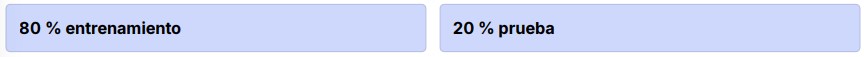

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.20,
random_state=42,
stratify=y
)

## ¿POR QUÉ ENTRENAMIENTO Y PRUEBA?
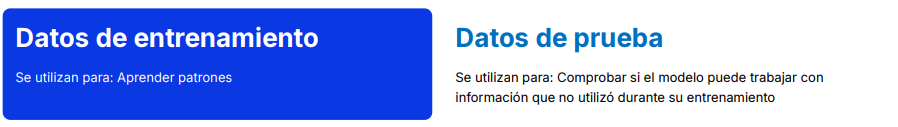

La verdadera finalidad del Machine Learning no es memorizar datos.

Debe ser capaz de: **generalizar**.

### PASO 10. CREAR EL MODELO

Utilizaremos: ***Regresión Logística***

Aunque su nombre contiene la palabra regresión, se utiliza principalmente para problemas de clasificación binaria.


In [40]:
modelo = make_pipeline(
StandardScaler(),
LogisticRegression(max_iter=1000)
)

### ¿POR QUÉ STANDARD SCALER?

Las variables poseen diferentes escalas.

Por ejemplo:


|Variable|ValorEjemplo
|---|---|
|Temperatura|80|
|Vibración|3.8|
|Horas de Operación|4200|

StandardScaler transforma las variables para que puedan compararse en escalas estadísticas compatibles.

## PASO 11. ENTRENAR

In [41]:
modelo.fit(
X_train,
y_train
)

,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


Durante este proceso el algoritmo analiza la relación entre las características y las fallas históricas.

## PASO 12. GENERAR PREDICCIONES

In [42]:
predicciones = modelo.predict(X_test)
print(predicciones)

[0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]


Ejemplo 

> [0 0 1 0 1 1 0]

Interpretación:

> `0` = funcionamiento *normal*  
> `1` = posible falla

## PASO 13. CALCULAR PROBABILIDADES

In [43]:
probabilidades = modelo.predict_proba(X_test)[:, 1]
print(probabilidades)


[0.3467479  0.10827615 0.22698473 0.28559279 0.27875535 0.37545091
 0.2391774  0.54340082 0.23585979 0.27382485 0.20267584 0.28923644
 0.14013565 0.43962286 0.50679148 0.17819139 0.2830276  0.2725274
 0.4777746  0.38589576 0.1467976  0.25940439 0.46026921 0.28536689
 0.2536628  0.53616044 0.30276938 0.28661339 0.21586986 0.20120111
 0.21798802 0.30310009 0.35884722 0.20721963 0.20829552 0.17027686
 0.36035144 0.40424062 0.20433964 0.28493572 0.4277785  0.42495425
 0.21418888 0.12694507 0.44362547 0.39509253 0.23548298 0.4427727
 0.38249938 0.22640171 0.21183711 0.30464057 0.42860757 0.35029062
 0.33833159 0.14815928 0.21374112 0.27008103 0.22771837 0.5024841
 0.44882715 0.21340579 0.23805808 0.41196754 0.36547848 0.23052367
 0.20105798 0.21926826 0.40312266 0.42407037 0.41778671 0.37659857
 0.20978937 0.25530266 0.36502404 0.22818542 0.16142713 0.32891158
 0.2451086  0.32817741 0.2530708  0.35221293 0.18551091 0.2987147
 0.20254347 0.3369755  0.37231908 0.27170345 0.24871462 0.33416183

Ejemplo 

> 0.12 0.18 0.87 0.31 0.91

Interpretación:

> `0.12` = 12% de probabilidad de falla  
> `0.87` = 87% de probabilidad de falla

## PASO 14. TOMAR UNA DECISIÓN

In [44]:
for probabilidad in probabilidades:
    if probabilidad >= 0.80:
        print("Mantenimiento urgente")
    elif probabilidad >= 0.50:
        print("Programar inspección")
    else:
        print("Funcionamiento normal")

Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Programar inspección
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Programar inspección
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Programar inspección
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamiento normal
Funcionamient

Aquí observamos cómo diferentes conocimientos trabajan conjuntamente:
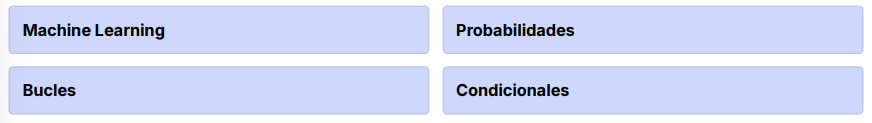

## PASO 15. EVALUAR EL MODELO

### Exactitud

In [45]:
accuracy = accuracy_score(
y_test,
predicciones
)
print("Accuracy:", accuracy)

Accuracy: 0.695


Si obtenemos: 0.91 significa que aproximadamente: 91 % de las predicciones evaluadas fueron correctas.

Sin embargo, la exactitud por sí sola no siempre es suficiente, especialmente si existen pocas fallas frente a una gran cantidad de registros
normales.


### MATRIZ DE CONFUSIÓN

In [46]:
matriz = confusion_matrix(
y_test,
predicciones
)
print(matriz)

[[137   4]
 [ 57   2]]


### REPORTE DE CLASIFICACIÓN

In [47]:
print(
    classification_report(
        y_test,
        predicciones,
        zero_division=0)
    )

              precision    recall  f1-score   support

           0       0.71      0.97      0.82       141
           1       0.33      0.03      0.06        59

    accuracy                           0.69       200
   macro avg       0.52      0.50      0.44       200
weighted avg       0.60      0.69      0.59       200



Presenta métricas como:
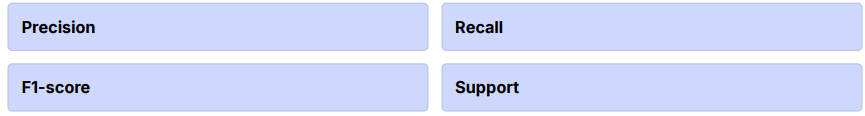

## PASO 16. PROBAR UNA NUEVA MÁQUINA

Supongamos:

> Temperatura = 91  
> Vibración = 5.5  
> Presión = 39  
> Horas = 4100  
> Días desde mantenimiento = 95  

Creamos el registro:

In [48]:
nueva_maquina = pd.DataFrame(
[{
        "temperatura": 91,
        "vibracion": 5.5,
        "presion": 39,
        "horas_operacion": 4100,
        "dias_mantenimiento": 95
    }]
)


Predicción:

In [57]:
resultado = modelo.predict(
    nueva_maquina
)[0]
print("Resultado de predicción: ",resultado)

Resultado de predicción:  0


Probabilidad:

In [58]:
probabilidad = modelo.predict_proba(
    nueva_maquina
)[0][1]
print("Probabilidad: ",probabilidad)

Probabilidad:  0.3179919246958612


Mostrar resultado:

In [59]:
print(
    "Probabilidad de falla:",
    round(probabilidad * 100, 2),
    "%"
)


Probabilidad de falla: 31.8 %


## PASO 17. GENERAR RECOMENDACIÓN

In [52]:
if probabilidad >= 0.80:
    print("ALERTA: realizar mantenimiento urgente.")
elif probabilidad >= 0.50:
    print("ADVERTENCIA: programar inspección.")
else:
    print("Máquina dentro del comportamiento esperado.")

Máquina dentro del comportamiento esperado.


## PASO 18. EXPORTAR RESULTADOS A CSV

In [53]:
resultados = X_test.copy()
resultados["real"] = y_test.values
resultados["prediccion"] = predicciones
resultados["probabilidad_falla"] = probabilidades

Exportar:

In [54]:
resultados.to_csv(
    "resultado_predicciones.csv",
    index=False
)
